# Predicting blood donations

A mobile blood donation vehicle in Taiwan visits university campuses. Given a donor's history, can we predict whether they will donate on the next visit? Good predictions would help a blood service forecast supply and decide who to contact.

The data is the [Blood Transfusion Service Center dataset](https://archive.ics.uci.edu/ml/datasets/Blood+Transfusion+Service+Center) from UCI: 748 donors, four features and a binary target.

## 1. Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

transfusion = pd.read_csv("datasets/transfusion.data")
transfusion.head()

,Recency (months),Frequency (times),Monetary (c.c. blood),Time (months),whether he/she donated blood in March 2007
0,2,50,12500,98,1
1,0,13,3250,28,1
2,1,16,4000,35,1
3,2,20,5000,45,1
4,1,24,6000,77,0


The features follow the RFM scheme used in marketing:

- **Recency**: months since the last donation
- **Frequency**: total number of donations
- **Monetary**: total blood donated, in c.c.
- **Time**: months since the first donation

The column names are shortened to make them easier to work with.

In [2]:
transfusion.columns = ["recency", "frequency", "monetary", "time", "target"]
transfusion.info()

<class 'pandas.DataFrame'>
RangeIndex: 748 entries, 0 to 747
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   recency    748 non-null    int64
 1   frequency  748 non-null    int64
 2   monetary   748 non-null    int64
 3   time       748 non-null    int64
 4   target     748 non-null    int64
dtypes: int64(5)
memory usage: 29.3 KB


## 2. Target balance

Only about 24% of donors gave blood in March 2007. Accuracy would be misleading here (always predicting "no" scores 76%), so models are compared on ROC AUC, and the train/test split is stratified.

In [3]:
transfusion["target"].value_counts(normalize=True).round(3)

target
0    0.762
1    0.238
Name: proportion, dtype: float64

## 3. A redundant feature

Every donation is 250 c.c., so `monetary` is just `frequency * 250` and adds no information.

In [4]:
print("monetary == frequency * 250 for every row:", (transfusion["monetary"] == transfusion["frequency"] * 250).all())
transfusion.corr().round(2)

monetary == frequency * 250 for every row: True


,recency,frequency,monetary,time,target
recency,1.00,-0.18,-0.18,0.16,-0.28
frequency,-0.18,1.00,1.00,0.63,0.22
monetary,-0.18,1.00,1.00,0.63,0.22
time,0.16,0.63,0.63,1.00,-0.04
target,-0.28,0.22,0.22,-0.04,1.00


`monetary` is dropped. Two derived features are added: the donation rate (donations per month since the first one) and the log of frequency, since frequency is heavily right-skewed.

In [5]:
features = transfusion.drop(columns=["monetary", "target"]).copy()
features["rate"] = features["frequency"] / features["time"]
features["log_frequency"] = np.log(features["frequency"])
target = transfusion["target"]

features.describe().round(2)

,recency,frequency,time,rate,log_frequency
count,748.00,748.00,748.00,748.00,748.00
mean,9.51,5.51,34.28,0.20,1.29
std,8.10,5.84,24.38,0.15,0.91
min,0.00,1.00,2.00,0.01,0.00
25%,2.75,2.00,16.00,0.09,0.69
50%,7.00,4.00,28.00,0.15,1.39
75%,14.00,7.00,50.00,0.25,1.95
max,74.00,50.00,98.00,1.00,3.91


## 4. Train/test split

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    features, target, test_size=0.25, random_state=42, stratify=target
)
X_train.shape, X_test.shape

((561, 5), (187, 5))

## 5. Compare models

Three candidates, each scored with stratified 5-fold cross-validation on the training set:

- logistic regression on the three raw features
- logistic regression on all five features
- gradient boosting on all five features

In [7]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

raw_cols = ["recency", "frequency", "time"]
all_cols = list(features.columns)

candidates = {
    "logreg (raw features)": (make_pipeline(StandardScaler(), LogisticRegression()), raw_cols),
    "logreg (engineered features)": (make_pipeline(StandardScaler(), LogisticRegression()), all_cols),
    "gradient boosting": (GradientBoostingClassifier(random_state=42), all_cols),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}
for name, (model, cols) in candidates.items():
    scores = cross_val_score(model, X_train[cols], y_train, cv=cv, scoring="roc_auc")
    cv_results[name] = {"cv_auc_mean": scores.mean(), "cv_auc_std": scores.std()}

cv_results = pd.DataFrame(cv_results).T.sort_values("cv_auc_mean", ascending=False).round(3)
cv_results

,cv_auc_mean,cv_auc_std
logreg (engineered features),0.754,0.046
logreg (raw features),0.737,0.053
gradient boosting,0.691,0.037


## 6. Test-set performance

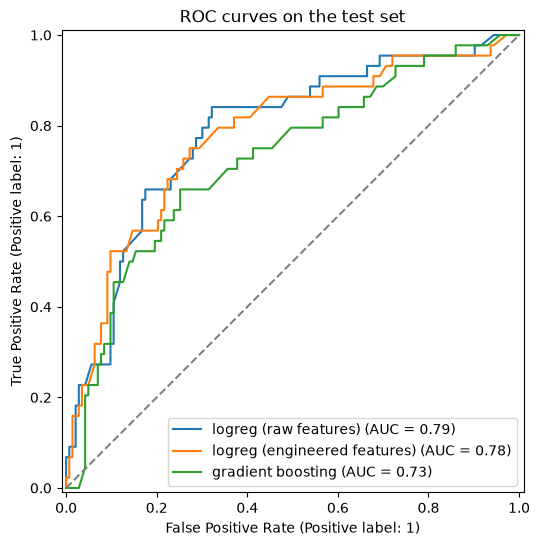

logreg (raw features)           0.786
logreg (engineered features)    0.778
gradient boosting               0.726
Name: test_auc, dtype: float64

In [8]:
from sklearn.metrics import RocCurveDisplay, roc_auc_score

fig, ax = plt.subplots(figsize=(6, 6))
test_auc = {}
for name, (model, cols) in candidates.items():
    model.fit(X_train[cols], y_train)
    proba = model.predict_proba(X_test[cols])[:, 1]
    test_auc[name] = roc_auc_score(y_test, proba)
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color="grey")
ax.set_title("ROC curves on the test set")
plt.show()

pd.Series(test_auc, name="test_auc").sort_values(ascending=False).round(3)

## 7. What drives the prediction?

Standardised coefficients of the logistic regression with engineered features.

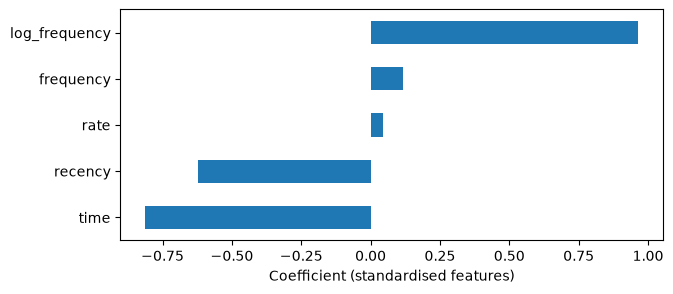

In [9]:
logreg = candidates["logreg (engineered features)"][0]
coefs = pd.Series(logreg[-1].coef_[0], index=all_cols).sort_values()
coefs.plot.barh(figsize=(7, 3))
plt.xlabel("Coefficient (standardised features)")
plt.show()

## Conclusion

- With only 748 donors and three independent features, logistic regression beats gradient boosting in cross-validation and on the test set (AUC about 0.78 against 0.73). The engineered features give a small gain in cross-validation that does not carry over to the test set, so the difference between the two logistic models is within noise.
- The longer since someone last donated, the less likely they are to return. More past donations raise the probability, and for the same number of donations, a donor who started longer ago is less likely to give again.
- An AUC just under 0.8 is useful for ranking donors for outreach, but not accurate enough to predict individual behaviour.